> 📖 Book: [ch02 – Eigen, SVD](../../.claude/skills/ml-knowledge/chapters/ch02-linear-algebra-eigen-svd.md) · Prev: [05](05_svd_low_rank_and_dynamical_systems.ipynb) · Next: [01_linear_regression](../01_linear_regression/01_normal_equations.ipynb)

# Numerical Linear Algebra in Practice

[03 §4](03_linear_inversion_problem.ipynb) listed the methods for solving $A\mathbf{x} = \mathbf{b}$ (LU, QR, SVD, CG), and notebooks [04](04_orthogonal_and_unitary_matrices.ipynb) and [05](05_svd_low_rank_and_dynamical_systems.ipynb) call `np.linalg.svd` and `np.fft.fft` as if they were free. They are not, and how they are computed is a subject of its own: **who actually implements these algorithms, and how do they get so fast?**

The short answer: the heavy lifting is done by decades-old, carefully tuned libraries written mostly in **Fortran and C**, and Python is the interface on top. Two implementations of the *same* algorithm, with the *same* asymptotic complexity, can differ in speed by orders of magnitude. Speed depends on three things at once:

1. **The mathematics:** which algorithm, and its operation count (§4, §5).
2. **The hardware:** memory hierarchy, vector instructions, cores (§2, §3).
3. **The implementation:** code that maps 1 onto 2 (§1, §6).

The timings below depend on the machine; the trends are what matter.

In [1]:
import timeit

import matplotlib.pyplot as plt
import numpy as np
import scipy.fft
import scipy.linalg
from sklearn.utils.extmath import randomized_svd

from ml.linalg import dft_matrix, matmul_naive

plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(0)


def best_time(f, repeat=5):
    # ponytail: min of a few runs, no warm-up control; enough to show orders of magnitude
    return min(timeit.repeat(f, number=1, repeat=repeat))

## 1. Who actually runs `np.linalg.svd`?

```python
U, S, VT = np.linalg.svd(A)
```

looks like Python doing the work, but the call goes down a stack:

```text
        Python            your code: orchestration, experimentation
          │
        NumPy             array object, dispatch
          │
   LAPACK interface       thin wrapper
          │
   LAPACK  /  BLAS        the algorithms (Fortran / C)
          │
 optimized BLAS kernels   OpenBLAS, Intel MKL, Apple Accelerate…
          │
         CPU
```

- **BLAS** (*Basic Linear Algebra Subprograms*) implements the building blocks: vector operations (level 1), matrix–vector products (level 2) and matrix–matrix products (level 3).
- **LAPACK** (*Linear Algebra PACKage*) implements the algorithms built on top of BLAS: LU, QR, Cholesky, eigenvalue problems, least squares and the SVD. It is written mainly in Fortran 90, with a lot inherited from Fortran 77. Its routine names encode their job: `DGESVD` is **D**ouble precision, **GE**neral matrix, **SVD**; `DGESDD` is the divide-and-conquer variant.

`np.show_config()` shows which BLAS/LAPACK build this NumPy is linked against.

In [2]:
np.show_config()

Build Dependencies:
  blas:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.12.13/lib/python3.12/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.12.13/lib/python3.12/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.34.106.0  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.34.106.0
  lapack:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.12.13/lib/python3.12/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.12.13/lib/python3.12/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.34.106.0  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.34.106.0
Compilers:
  c:
    commands: 

## 2. Same $O(n^3)$, very different constant

The textbook matrix product $C_{ij} = \sum_k A_{ik}B_{kj}$ is three nested loops, $n^3$ multiply–adds. `ml.linalg.matmul_naive` writes exactly that in pure Python. `A @ B` calls BLAS `dgemm`, which performs the **same** $n^3$ multiply–adds. Both lines below grow like $n^3$, yet they are separated by a factor of thousands.

The gap is not the language alone. An optimized `dgemm`:

- **blocks** the matrices into tiles that fit in cache, so each number fetched from memory is reused many times (§3);
- uses **SIMD** instructions (*Single Instruction, Multiple Data*): one instruction multiplies 4, 8 or 16 numbers at once, e.g. $a_1b_1, a_2b_2, a_3b_3, a_4b_4$ in one step;
- runs on **several cores** at once (multithreading);
- has inner kernels hand-tuned, often in assembly, for each processor family.

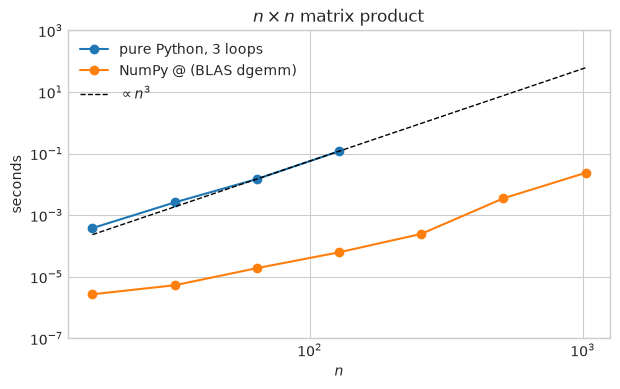

n = 128: naive / BLAS = 1,919x


In [3]:
sizes = [16, 32, 64, 128]
t_naive = [best_time(lambda n=n: matmul_naive(*rng.normal(size=(2, n, n))), repeat=2) for n in sizes]
sizes_blas = [16, 32, 64, 128, 256, 512, 1024]
t_blas = [best_time(lambda n=n, M=rng.normal(size=(n, n)): M @ M) for n in sizes_blas]

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(sizes, t_naive, "o-", label="pure Python, 3 loops")
ax.loglog(sizes_blas, t_blas, "o-", label="NumPy @ (BLAS dgemm)")
ref = np.array(sizes_blas, dtype=float)
ax.loglog(ref, t_naive[-1] * (ref / sizes[-1]) ** 3, "k--", lw=1, label="$\\propto n^3$")
ax.set(xlabel="$n$", ylabel="seconds", title="$n \\times n$ matrix product", ylim=(1e-7, 1e3))
ax.legend()
plt.show()
print(f"n = {sizes[-1]}: naive / BLAS = {t_naive[-1] / t_blas[sizes_blas.index(sizes[-1])]:,.0f}x")

## 3. The memory hierarchy: moving data costs more than arithmetic

A processor stores data at several levels, each larger and slower than the previous one (typical orders of magnitude):

| Level | Size | Latency |
|---|---|---|
| Registers | bytes | < 1 ns |
| L1 cache | tens of KB | ~1 ns |
| L2 cache | ~1 MB | a few ns |
| L3 cache | tens of MB | ~10 ns |
| RAM | GB | ~100 ns |

Data travels between levels in **cache lines** of 64 bytes (8 doubles). Reading memory in order uses every number in a line; jumping around wastes most of it. Often the bottleneck is not the number of operations but how long the processor waits for its data, which is why an algorithm with fewer operations can be slower if it accesses memory badly.

NumPy stores a 2-D array row by row (C order). The cell copies the same $4000\times4000$ array two ways: in memory order, and transposed, which walks down columns with a stride of 32 KB. Same data, same number of operations.

contiguous copy: 11.7 ms | strided (transposed) copy: 181.8 ms


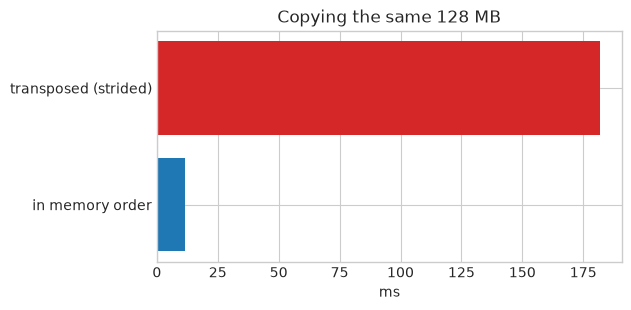

In [4]:
M = rng.normal(size=(4000, 4000))
out = np.empty_like(M)
t_contiguous = best_time(lambda: np.copyto(out, M))
t_strided = best_time(lambda: np.copyto(out, M.T))
print(f"contiguous copy: {t_contiguous * 1e3:.1f} ms | strided (transposed) copy: {t_strided * 1e3:.1f} ms")

fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["in memory order", "transposed (strided)"], [t_contiguous * 1e3, t_strided * 1e3], color=["C0", "C3"])
ax.set(xlabel="ms", title="Copying the same 128 MB")
plt.show()

## 4. Choosing the algorithm, not the language

There is no single "SVD algorithm". The main strategies are genuinely different computations:

- **Bidiagonalization + QR iteration** (`gesvd`): reduce $A$ to bidiagonal form with orthogonal (Householder) transformations, then iterate. Robust, the classic.
- **Divide and conquer** (`gesdd`): split the bidiagonal problem into halves, solve, merge. Usually much faster when the singular vectors are needed, at the price of more memory.
- **Jacobi SVD:** a sequence of $2\times2$ rotations; slower but very accurate for small singular values.
- **Randomized SVD:** project onto a random low-dimensional subspace first, then factor the small matrix. Only computes the top $r$ components, which is exactly what low-rank approximation needs ([05 §4](05_svd_low_rank_and_dynamical_systems.ipynb)).

Notice that every step of the first two uses **orthogonal** transformations ([04](04_orthogonal_and_unitary_matrices.ipynb)): since $\kappa(Q) = 1$, they do not amplify rounding errors, which is why these algorithms are numerically stable.

SciPy lets you pick the LAPACK driver: you are not running an SVD written in Python, you are **choosing which compiled implementation** to call.

same singular values (gesvd vs gesdd): True


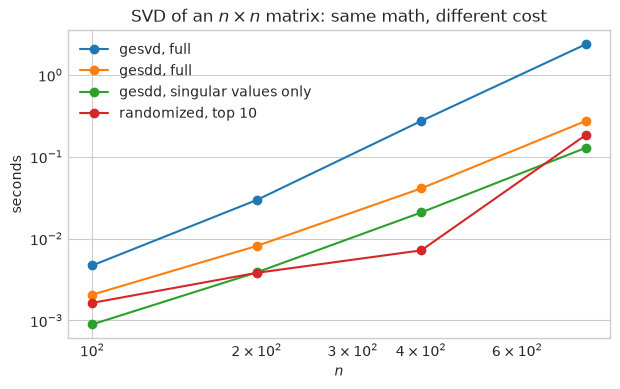

In [5]:
n_svd = [100, 200, 400, 800]
variants = {
    "gesvd, full": lambda A: scipy.linalg.svd(A, lapack_driver="gesvd"),
    "gesdd, full": lambda A: scipy.linalg.svd(A, lapack_driver="gesdd"),
    "gesdd, singular values only": lambda A: scipy.linalg.svd(A, compute_uv=False),
    "randomized, top 10": lambda A: randomized_svd(A, 10, random_state=0),
}
times = {name: [] for name in variants}
for n in n_svd:
    A = rng.normal(size=(n, n))
    for name, f in variants.items():
        times[name].append(best_time(lambda f=f, A=A: f(A), repeat=3))

A = rng.normal(size=(300, 200))
s_gesvd = scipy.linalg.svd(A, compute_uv=False, lapack_driver="gesvd")
s_gesdd = scipy.linalg.svd(A, compute_uv=False, lapack_driver="gesdd")
print("same singular values (gesvd vs gesdd):", np.allclose(s_gesvd, s_gesdd))

fig, ax = plt.subplots(figsize=(7, 4))
for name, t in times.items():
    ax.loglog(n_svd, t, "o-", label=name)
ax.set(xlabel="$n$", ylabel="seconds", title="SVD of an $n\\times n$ matrix: same math, different cost")
ax.legend()
plt.show()

## 5. The FFT: an algorithm that changes the exponent

[04 §7](04_orthogonal_and_unitary_matrices.ipynb) wrote the DFT as $\hat{\mathbf{x}} = F\mathbf{x}$: a dense matrix–vector product, $O(N^2)$. The **fast Fourier transform** computes the same vector in $O(N\log N)$ by exploiting the structure of $F$. Here the mathematics, not the implementation, makes the difference, and it grows with $N$: at $N = 2^{20}$ it is $N/\log_2N \approx 50{,}000$ times fewer operations. (For tiny $N$ the fixed cost of a function call dominates, and the plain matrix product can even win.)

The FFT is not one algorithm either:

- **Cooley–Tukey:** factor $N = N_1N_2$ and split recursively into smaller transforms; ideal when $N = 2^{10} = 1024$ factors into small primes.
- **Split-radix:** a refinement for powers of two with fewer operations.
- **Prime-factor algorithm:** for $N$ with coprime factors.
- **Rader** and **Bluestein:** turn a prime-length DFT into a convolution of composite length, so even $N = 997$ stays $O(N\log N)$, with a larger constant.

So the factorization of $N$ matters, which the second figure shows: lengths built from small primes are fastest, primes are slower (but still nowhere near $O(N^2)$). `scipy.fft.next_fast_len` returns the next "nice" length for zero-padding.

F x == FFT (orthonormal scaling): True


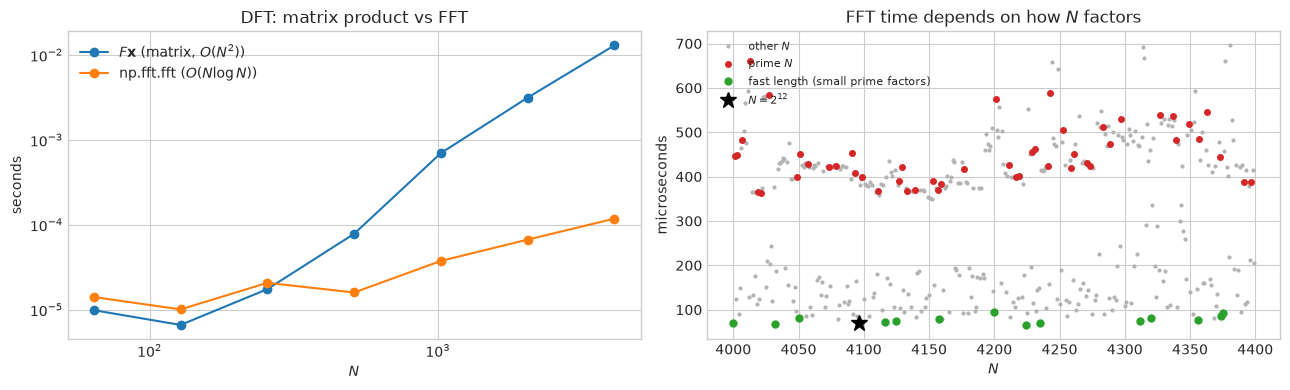

In [6]:
Ns = [64, 128, 256, 512, 1024, 2048, 4096]
t_matrix, t_fft = [], []
for N in Ns:
    F, x = dft_matrix(N), rng.normal(size=N)
    t_matrix.append(best_time(lambda F=F, x=x: F @ x))
    t_fft.append(best_time(lambda x=x: np.fft.fft(x)))
print("F x == FFT (orthonormal scaling):", np.allclose(F @ x, np.fft.fft(x, norm="ortho")))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].loglog(Ns, t_matrix, "o-", label="$F\\mathbf{x}$ (matrix, $O(N^2)$)")
ax[0].loglog(Ns, t_fft, "o-", label="np.fft.fft ($O(N\\log N)$)")
ax[0].set(xlabel="$N$", ylabel="seconds", title="DFT: matrix product vs FFT")
ax[0].legend()


def is_prime(n):
    return n > 1 and all(n % p for p in range(2, int(n**0.5) + 1))


lengths = np.arange(4000, 4400)
t_len = np.array([best_time(lambda x=rng.normal(size=N): np.fft.fft(x), repeat=7) for N in lengths])
primes = np.array([is_prime(N) for N in lengths])
smooth = np.array([scipy.fft.next_fast_len(int(N)) == N for N in lengths])
ax[1].plot(lengths, t_len * 1e6, ".", c="0.7", ms=4, label="other $N$")
ax[1].plot(lengths[primes], t_len[primes] * 1e6, "o", c="C3", ms=4, label="prime $N$")
ax[1].plot(lengths[smooth], t_len[smooth] * 1e6, "o", c="C2", ms=5, label="fast length (small prime factors)")
ax[1].plot(4096, t_len[lengths == 4096][0] * 1e6, "k*", ms=12, label="$N = 2^{12}$")
ax[1].set(xlabel="$N$", ylabel="microseconds", title="FFT time depends on how $N$ factors")
ax[1].legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## 6. Libraries and languages

### 6.1 FFTW and planning

**FFTW** (*The Fastest Fourier Transform in the West*, written in C) does not run one fixed FFT. It **plans**: before transforming many signals of the same size, it tries several decompositions on your hardware, measures them, and keeps the fastest. Its inner kernels ("codelets") are themselves produced by a code generator, specialized per size and instruction set.

```text
          FFTW
            │
       FFT planner ── explores alternatives for this N, on this CPU
            │
   ┌────────┼────────┐
 radix-2  radix-4  split-radix …
   └────────┼────────┘
            │
   measures, keeps the fastest
            │
      FFT executor  ── reused for every transform of size N
```

Planning costs time once and pays off when the same transform is repeated, the trade-off that recurs throughout high-performance computing.

### 6.2 The landscape

| Library | Main language | Hardware | Role |
|---|---|---|---|
| Reference BLAS / LAPACK | Fortran | CPU | the standard interfaces and algorithms |
| OpenBLAS | C, assembly | CPU | optimized open-source BLAS (+ LAPACK) |
| Intel oneMKL | C, Fortran | Intel CPU, GPU | BLAS, LAPACK, FFT |
| FFTW | C | CPU | FFT with planning |
| PocketFFT | C++ | CPU | the FFT behind `numpy.fft` and `scipy.fft` |
| cuBLAS, cuFFT, cuSOLVER | CUDA C++ | NVIDIA GPU | GPU linear algebra and FFT |
| rocFFT | C++ | AMD GPU | GPU FFT |

| Language | Typical use |
|---|---|
| Fortran | numerical linear algebra, scientific computing |
| C | numerical libraries, low-level optimization |
| C++ | scientific computing, ML frameworks, parallel processing |
| CUDA C++ | NVIDIA GPU computing |
| Julia | scientific computing in a high-level language that compiles to fast code |
| Python | interfaces, experimentation, orchestration |

A high-level language does not imply low performance. What matters is **where the computationally intensive code actually runs**. In Python, the rule is to push the loops down into one of these libraries (vectorize) and keep Python for orchestration.

**GPU caveat.** Comparing CPU and GPU, separate the time to transfer data to the device from the compute time. For small transforms, sending the data to the GPU can cost more than doing the whole FFT on the CPU.

**Exercise** (for `notebooks/experiments/`, logged with MLflow): benchmark `numpy.fft`, `scipy.fft`, pyFFTW and, if a GPU is available, CuPy for $N \in \{2^{10}, 2^{12}, \dots, 2^{20}\}$, measuring time, memory, error against a reference, and repeated transforms.

## 7. Takeaway

```text
Mathematics                      DFT, SVD, QR, LU …
    │
    ▼
Numerical algorithm              FFT, divide & conquer, Householder, randomized …
    │
    ▼
Implementation                   blocking, data layout, generated kernels
    │
    ▼
Memory and CPU optimization      cache, SIMD, threads, GPU
    │
    ▼
Scientific libraries             BLAS, LAPACK, FFTW, MKL, cuFFT
    │
    ▼
High-level interfaces            NumPy, SciPy, MATLAB, Julia
```

Studying SVD, QR, LU or the FFT is studying more than mathematics: these are algorithms carefully designed to turn mathematical operations into instructions the hardware runs efficiently. The meeting point of numerical analysis (stable, efficient algorithms), computer architecture (memory, caches, SIMD, parallelism) and compilers (translating algorithms into optimized instructions) is called **high-performance computing**.

**To go further:**

1. [LAPACK](https://www.netlib.org/lapack/) and the [`DGESVD` documentation](https://www.netlib.org/lapack/explore-html/d1/d7f/group__gesvd_gac6bd5d4e645049e49bb70691180abf07.html): real implementations of matrix algorithms.
2. [BLAS](https://www.netlib.org/blas/): the basic building blocks.
3. [`scipy.linalg.svd`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.svd.html): how the drivers reach Python.
4. [FFTW](https://www.fftw.org/), [PocketFFT](https://github.com/mreineck/pocketfft), [NVIDIA cuFFT](https://docs.nvidia.com/cuda/cufft/index.html), [Intel oneMKL](https://www.intel.com/content/www/us/en/developer/tools/oneapi/onemkl.html). FFTW's planner is an excellent case study in high-performance scientific software.